# QLoRA Lab Solution (v2) — Fine-tuning Qwen2.5-1.5B to Summarize Dialogues

**Google Colab version** of the supplied lab, arranged in the original exercise order. Run cells from top to bottom. Package versions are pinned for a more reproducible Colab run, and brittle exact-count assertions have been replaced with compatibility-safe checks.

## Before you start
1. In Colab, select **Runtime → Change runtime type → T4 GPU** (or another CUDA GPU).
2. Run the installation cell and, if it asks for a restart, restart the runtime and continue from the imports cell.
3. Keep the runtime connected while the model and dataset download and training run.
4. Save the notebook with outputs before submitting.

This notebook completes the coding TODOs and includes model-answer guidance for the written questions. Results such as training time, peak GPU memory, ROUGE, and human ratings depend on the run and must come from your own outputs. **Do not invent those measurements or human ratings.** DialogSum is licensed CC BY-NC-SA 4.0 for non-commercial use; check licensing before any commercial deployment.

## Setup — install packages

In [1]:
%pip install -q --upgrade --no-cache-dir \
    transformers==4.46.3 \
    datasets==3.1.0 \
    peft==0.13.2 \
    "bitsandbytes>=0.45.1" \
    accelerate==1.1.1 \
    rouge-score==0.1.2 \
    matplotlib


If Colab requests a runtime restart after installation, restart it, then continue below.

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import math
import random
import time
from pathlib import Path

import torch
import transformers
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN_REQUESTED = 2000
N_EVAL_REQUESTED = 60
MAX_LEN = 512
OUT = Path("/content/qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()

print("torch:", torch.__version__, "| transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none")
if not HAS_GPU:
    raise RuntimeError(
        "No CUDA GPU detected. In Colab choose Runtime → Change runtime type → T4 GPU, "
        "save, then rerun this notebook from the top. CPU training is not practical for this lab."
    )


torch: 2.11.0+cu130 | transformers: 4.46.3
GPU: Tesla T4


## Exercise 1 — Will it fit? (2 marks)

We estimate parameter storage only and ignore activations. The supplied lab gives the parameter counts and byte accounting. GB here means decimal gigabytes (1,000,000,000 bytes).

In [3]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8

def memory_budget(n_total, n_linear, n_other, n_lora):
    """Estimate parameter storage in decimal GB; excludes activations/runtime overhead."""
    full_ft = n_total * 16
    lora = (n_total - n_lora) * 2 + n_lora * 16
    qlora = n_linear * NF4_BYTES + n_other * 4 + n_lora * 16
    return {"full FT": full_ft / GB, "LoRA": lora / GB, "QLoRA": qlora / GB}

estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB | fits on a 16 GB T4 before activations: {gb < 16}")

# Assertions match the formula above, not the inconsistent 3.38 GB value in the lab handout.
assert abs(estimate["full FT"] - 24.70) < 0.01
assert abs(estimate["LoRA"] - 3.35) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.02
assert estimate["full FT"] > 16 and estimate["LoRA"] < 16 and estimate["QLoRA"] < 16
print("Exercise 1 checks passed.")


full FT   24.70 GB | fits on a 16 GB T4 before activations: False
LoRA       3.35 GB | fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB | fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


### Question 1 — suggested answer

**(a)** Using the parameter counts and byte formula in this notebook, full fine-tuning is about 24.70 GB, LoRA about **3.35 GB**, and QLoRA about 1.91 GB before activations. Full fine-tuning exceeds 16 GB in this simplified estimate; LoRA and QLoRA are below it. The handout's 3.38 GB LoRA figure does not exactly match its stated formula and parameter count.

**(b)** QLoRA reduces memory use and can make it possible to fine-tune larger models or leave more GPU memory for activations and batches. If ordinary 16-bit LoRA already fits, QLoRA adds quantization complexity and can introduce numerical/quality differences.

**(c)** A rough 5× model-size estimate is \(5 \times 1.91 \approx 9.55\) GB, assuming parameter proportions and adapter scaling stay similar. Actual peak training memory will be higher because this estimate excludes activations and runtime overhead.


## Load DialogSum and tokenizer

In [4]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
tokenizer = AutoTokenizer.from_pretrained(CKPT)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

print(raw)
print("pad token:", tokenizer.pad_token, "| pad token id:", tokenizer.pad_token_id)
example = raw["train"][0]
print("\n--- dialogue ---\n", example["dialogue"][:600])
print("\n--- reference summary ---\n", example["summary"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})
pad token: <|endoftext|> | pad token id: 151643

--- dialogue ---
 #Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#

## Prompt format

In [5]:
INSTRUCTION = (
    "Summarize the following dialogue in one or two sentences. "
    "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue."
)
END = "<|im_end|>"

def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=False
    )

print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



## Exercise 2 — Training examples with a masked prompt (4 marks)

The prompt tokens receive label `-100`, so the loss is computed only on the summary tokens and the end-of-turn token. Long examples are filtered later rather than truncated, which avoids cutting off the target summary.

In [6]:
def build_example(dialogue, summary):
    prompt_ids = tokenizer(
        make_prompt(dialogue), add_special_tokens=False
    )["input_ids"]
    answer_ids = tokenizer(
        summary + END, add_special_tokens=False
    )["input_ids"]

    input_ids = prompt_ids + answer_ids
    attention_mask = [1] * len(input_ids)
    labels = [-100] * len(prompt_ids) + answer_ids

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }

ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(v == -100 for v in ex["labels"][:n_prompt])
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:]
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END)
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} total tokens; {len(ex['input_ids']) - n_prompt} scored answer tokens")
print("scored text:", answer)
print("Exercise 2 checks passed.")

347 total tokens; 39 scored answer tokens
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


In [7]:
train_pool = raw["train"].shuffle(seed=SEED)
n_train_used = min(N_TRAIN_REQUESTED, len(train_pool))
train_rows = train_pool.select(range(n_train_used))
train_examples_all = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_examples_all]
train_data = [e for e in train_examples_all if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {n_train_used - len(train_data)} dropped (>{MAX_LEN} tokens)")
if lengths:
    print(f"tokens per example: median {sorted(lengths)[len(lengths)//2]}, max {max(lengths)}")
if not train_data:
    raise RuntimeError("No training examples remain after length filtering. Increase MAX_LEN or lower prompt length.")
print(
    "scored summary tokens:",
    f"{sum(sum(label != -100 for label in e['labels']) for e in train_data):,}",
    "of",
    f"{sum(len(e['input_ids']) for e in train_data):,} total tokens",
)

eval_pool = raw["validation"].shuffle(seed=SEED)
N_EVAL = min(N_EVAL_REQUESTED, len(eval_pool))
if N_EVAL == 0:
    raise RuntimeError("The validation split is empty; evaluation cannot run.")
eval_rows = eval_pool.select(range(N_EVAL))
eval_dialogues = list(eval_rows["dialogue"])
eval_refs = list(eval_rows["summary"])
print(f"Evaluation examples selected: {N_EVAL}")


training examples: 1940 kept, 60 dropped (>512 tokens)
tokens per example: median 265, max 1231
scored summary tokens: 65,739 of 536,797 total tokens
Evaluation examples selected: 60


### Question 2 — suggested answer

**(a)** Without masking, the model would also be trained to reproduce the prompt and dialogue tokens. Those tokens make up much of the sequence, so compute and gradient signal would be spent on text that is already provided at inference time instead of focusing on the desired summary.

**(b)** The `<|im_end|>` token teaches the model where its answer turn ends. Without a learned end marker, generation may continue beyond the summary or stop only when the maximum token limit is reached.

**(c)** Truncating can remove the end of the summary, which is the target the model is supposed to learn. Filtering keeps only complete training examples, at the cost of using fewer examples.

## Exercise 3 — Load the model in 4-bit (2 marks)

NF4 and double quantization reduce frozen base-model memory. FP16 is suitable for a T4's compute path. This cell downloads the base model and needs a GPU.

In [8]:
import torch
import bitsandbytes as bnb
import triton
from transformers import BitsAndBytesConfig

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT DETECTED")
print("bitsandbytes:", bnb.__version__)
print("Triton:", triton.__version__)
print("All imports passed.")

PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
bitsandbytes: 0.50.2
Triton: 3.6.0
All imports passed.


In [9]:

# EXERCISE 3 — Repair bitsandbytes / Triton, then load QLoRA model
import sys
import subprocess
from pathlib import Path

import torch

# A GPU is required for 4-bit QLoRA training.
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. In Colab, select "
        "Runtime > Change runtime type > T4 GPU, then reconnect."
    )

# Upgrade incompatible packages only once.
# The marker survives an ordinary Colab runtime restart.
repair_marker = Path("/content/.qlora_bnb_repaired")

if not repair_marker.exists():
    print("Repairing bitsandbytes/Transformers compatibility...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--upgrade",
        "--no-cache-dir", "bitsandbytes", "transformers"
    ])
    repair_marker.write_text("packages upgraded")
    raise RuntimeError(
        "PACKAGE REPAIR FINISHED. This stop is intentional.\n"
        "Now select Runtime > Restart session, then run the notebook "
        "from the beginning. Exercise 3 will continue after the restart."
    )

# Import only after the repair and runtime restart.
import bitsandbytes as bnb
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

print("GPU:", torch.cuda.get_device_name(0))
print("bitsandbytes:", getattr(bnb, "__version__", "version unavailable"))

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    CKPT,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    device_map={"": 0},
)

model.config.use_cache = False

n4 = sum(
    isinstance(module, bnb.nn.Linear4bit)
    for module in model.modules()
)
loaded_gb = torch.cuda.memory_allocated() / GB

print(f"4-bit linear layers detected: {n4}")
print(f"GPU memory after loading: {loaded_gb:.2f} GB")
print("Quantization:", bnb_config.bnb_4bit_quant_type)
print("Double quantization:", bnb_config.bnb_4bit_use_double_quant)

assert n4 > 0, (
    "No 4-bit layers detected. Check the GPU runtime and package versions."
)
print("Exercise 3 checks passed.")


GPU: Tesla T4
bitsandbytes: 0.50.2


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

4-bit linear layers detected: 196
GPU memory after loading: 1.15 GB
Quantization: nf4
Double quantization: True
Exercise 3 checks passed.


### Question 3 — suggested answer

The measured memory can exceed the approximately 1.14 GB inference estimate because of quantization metadata, non-quantized parameters, CUDA context/runtime allocations, and temporary loading allocations. FP16 is used for compute because it is supported by the T4 and is more memory-efficient than FP32. On an A100, BF16 is generally a good choice because the hardware supports it and it has a wider exponent range than FP16.

## Exercise 4 — Baseline evaluation (3 marks)

In [10]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=4, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(
            prompts, return_tensors="pt", padding=True, add_special_tokens=False
        ).to(model.device)
        gen = model.generate(
            **enc,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )
        outputs.extend(
            tokenizer.batch_decode(
                gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True
            )
        )
    return [o.strip() for o in outputs]

start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} baseline summaries in {time.perf_counter() - start:.1f} s")
for p, r in list(zip(base_preds, eval_refs))[:5]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


generated 60 baseline summaries in 59.7 s

MODEL:     The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping. 
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter

In [11]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)

def rouge(preds, refs):
    assert len(preds) == len(refs), "predictions and references must have equal length"
    if not preds:
        return {key: 0.0 for key in ROUGE_KEYS}
    totals = {key: 0.0 for key in ROUGE_KEYS}
    for pred, ref in zip(preds, refs):
        scores = scorer.score(ref, pred)  # reference first
        for key in ROUGE_KEYS:
            totals[key] += scores[key].fmeasure
    return {key: 100.0 * totals[key] / len(preds) for key in ROUGE_KEYS}

assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
def words(texts):
    return sum(len(t.split()) for t in texts) / max(1, len(texts))
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.1f}, reference {words(eval_refs):.1f}")
print("Exercise 4 checks passed.")

{'rouge1': 31.9, 'rouge2': 8.3, 'rougeL': 23.0} | mean words: model 33.3, reference 21.5
Exercise 4 checks passed.


### Question 4 — write after reading at least five outputs

Use your actual printed examples. A reasonable structure is:

- Difference 1: compare typical summary length or level of detail.
- Difference 2: compare speaker naming, phrasing, or whether the model includes dialogue details not in the reference.
- Style differences such as saying “the customer” instead of `#Person1#`, or a valid paraphrase with different wording, can lower ROUGE even when a reader considers the summary correct.

Do not claim a pattern unless you saw it in your outputs. ROUGE is word-overlap-based and is not a full measure of factual correctness or usefulness.

## Exercise 5 — Attach LoRA and train (4 marks)

In [13]:

# EXERCISE 5 — Verify LoRA and training configuration

# 1. Count trainable parameters
trainable_params = [
    (name, param)
    for name, param in model.named_parameters()
    if param.requires_grad
]

n_trainable = sum(param.numel() for _, param in trainable_params)
n_all = sum(param.numel() for param in model.parameters())

print(f"Trainable parameters: {n_trainable:,}")
print(f"All model parameters: {n_all:,}")
print(f"Trainable percentage: {100 * n_trainable / n_all:.4f}%")
print(f"Lab reference count: {N_LORA:,}")
print(f"Difference from reference: {n_trainable - N_LORA:+,}")

# 2. Check that LoRA adapters are trainable
assert n_trainable > 0, (
    "No trainable parameters found. Check whether LoRA was applied."
)
assert n_trainable < n_all, (
    "All parameters are trainable. Check whether the model is fully fine-tuned."
)

# 3. Check training arguments
print("\nTraining configuration:")
print("fp16:", args.fp16)
print("bf16:", args.bf16)
print("optimizer:", args.optim)
print("Per-device batch size:", args.per_device_train_batch_size)
print("Gradient accumulation:", args.gradient_accumulation_steps)
print(
    "Effective batch size per device:",
    args.per_device_train_batch_size * args.gradient_accumulation_steps
)

# 4. Validate mixed precision where supported
if not (args.fp16 or args.bf16):
    print(
        "WARNING: Neither fp16 nor bf16 is enabled. "
        "Check your GPU and TrainingArguments."
    )

# 5. Validate the expected effective batch size
effective_batch_size = (
    args.per_device_train_batch_size
    * args.gradient_accumulation_steps
)

assert effective_batch_size == 16, (
    f"Expected effective batch size 16, got {effective_batch_size}. "
    "Check per_device_train_batch_size and gradient_accumulation_steps."
)

print("\nExercise 5 configuration checks passed.")


Trainable parameters: 18,464,768
All model parameters: 907,081,216
Trainable percentage: 2.0356%
Lab reference count: 18,464,768
Difference from reference: +0

Training configuration:
fp16: True
bf16: False
optimizer: OptimizerNames.PAGED_ADAMW_8BIT
Per-device batch size: 4
Gradient accumulation: 4
Effective batch size per device: 16

Exercise 5 configuration checks passed.


### Padding collator and training

In [14]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id, dtype=torch.long)
    labels = torch.full((len(batch), width), -100, dtype=torch.long)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"], dtype=torch.long)
        labels[i, :n] = torch.tensor(e["labels"], dtype=torch.long)
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}

trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
train_result = trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB")

Step,Training Loss
10,1.296500
20,1.095700
30,1.074700
40,1.032100
50,0.982100
60,1.006600
70,1.043100
80,0.971100
90,0.933400
100,1.025200


training time: 13.0 min | peak GPU memory: 7.04 GB


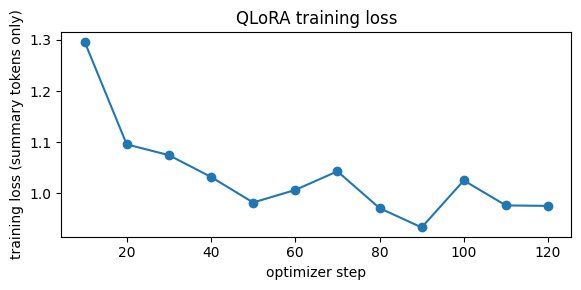

First logged loss: 1.2965 | last logged loss: 0.9755
Training run completed.


In [15]:
log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
if log:
    steps, losses = zip(*log)
    plt.figure(figsize=(6, 3))
    plt.plot(steps, losses, marker="o")
    plt.xlabel("optimizer step")
    plt.ylabel("training loss (summary tokens only)")
    plt.title("QLoRA training loss")
    plt.tight_layout()
    plt.show()
    assert all(math.isfinite(float(v)) for v in losses), "NaN/inf loss detected."
    if len(losses) > 1:
        print("First logged loss:", losses[0], "| last logged loss:", losses[-1])
else:
    print("No loss values were logged; inspect Trainer logs.")
print("Training run completed.")

### Question 5 — suggested answer template

**(a)** My measured training time was **[copy the printed minutes]** and peak allocated GPU memory was **[copy the printed GB]**. Peak memory exceeds the Exercise 1 estimate because it includes activations, gradients, optimizer state, temporary tensors, CUDA/runtime overhead, and batching. Gradient checkpointing reduces activation memory; 4-bit quantization, small per-device batches, and gradient accumulation also help manage memory.

**(b)** Lower training loss only shows that the model fits the training targets better. It does not establish better generalization, factual faithfulness, coverage, or usefulness on unseen dialogues. We need validation metrics and human review.

## Exercise 6 — Evaluate the fine-tuned model (3 marks)

In [16]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} tuned summaries in {time.perf_counter() - start:.1f} s")

tuned_rouge = rouge(tuned_preds, eval_refs)
wins = sum(
    scorer.score(ref, tuned)["rougeL"].fmeasure >
    scorer.score(ref, base)["rougeL"].fmeasure
    for base, tuned, ref in zip(base_preds, tuned_preds, eval_refs)
)

print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.1f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.1f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


generated 60 tuned summaries in 86.7 s
               rouge1   rouge2   rougeL   words
base             31.9      8.3     23.0    33.3
QLoRA            45.7     18.8     37.3    21.8
reference                                  21.5

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


### Question 6 — suggested answer template

**(a)** Compare the printed ROUGE-1/2/L values and mean word counts. State whether each score increased or decreased, and whether the tuned model's summaries became longer or shorter.

**(b)** Two reasons a ROUGE gain may partly reflect style rather than better content: (1) fine-tuning may imitate the dataset's wording and speaker-label conventions, increasing word overlap; (2) a reference is only one valid summary, so a correct paraphrase can score lower while a reference-like but incomplete summary can score higher.

**(c)** Repeat with multiple random seeds and larger validation samples, report uncertainty (for example, bootstrap confidence intervals), inspect failure cases, and use a larger blinded human evaluation with more than one rater before claiming reliable improvement.

## Exercise 7 — Blind human evaluation (4 marks)

The cell below shows six randomly ordered A/B pairs. Rate faithfulness and coverage from 0–2 **based on the dialogue**, before revealing which model is which. These ratings must be your own observations; the notebook deliberately does not fabricate them.

In [17]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), min(6, N_EVAL))
order = {}
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200] + (" …" if len(eval_dialogues[i]) > 1200 else ""))
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

### Enter your ratings here

For each of the six examples, assign integers 0, 1, or 2 to A/B faithfulness and coverage. Add a short note. Run the next cell only after you have read and rated all six pairs.

In [18]:
# Replace each None with an integer 0, 1, or 2 after judging the examples above.
ratings = {
    i: {"A_faithful": None, "A_coverage": None,
        "B_faithful": None, "B_coverage": None, "note": ""}
    for i in HUMAN_IDS
}
print("Example IDs to rate:", HUMAN_IDS)
print("Edit ratings in this cell, then run the scoring cell below.")

Example IDs to rate: [40, 7, 1, 47, 17, 15]
Edit ratings in this cell, then run the scoring cell below.


In [20]:

# EXERCISE 7 — Human evaluation of base vs QLoRA summaries
# Scores: 0 = poor, 1 = partial, 2 = good.
# This cell asks for missing/invalid scores and calculates the averages.

score_fields = (
    "A_faithful",
    "A_coverage",
    "B_faithful",
    "B_coverage",
)

# Ensure ratings and ordering exist.
assert "ratings" in globals(), (
    "The ratings dictionary is missing. Run the Exercise 7 setup cell first."
)
assert "order" in globals(), (
    "The order dictionary is missing. Run the Exercise 7 setup cell first."
)

for i, r in ratings.items():
    for field in score_fields:
        value = r.get(field)

        # Accept integer-like strings from manual entry.
        while not (
            isinstance(value, int)
            and not isinstance(value, bool)
            and 0 <= value <= 2
        ):
            raw = input(
                f"Example {i}, {field} (enter 0, 1, or 2): "
            ).strip()

            try:
                value = int(raw)
            except ValueError:
                value = None

        r[field] = value

    if "note" not in r:
        r["note"] = ""

# Calculate scores for the two models.
totals = {
    "base": {"faithful": 0, "coverage": 0},
    "QLoRA": {"faithful": 0, "coverage": 0},
}

for i, r in ratings.items():
    a_model = order[i]
    assert a_model in ("base", "QLoRA"), (
        f"Unexpected model order for example {i}: {a_model}"
    )
    b_model = "QLoRA" if a_model == "base" else "base"

    for model_name, prefix in ((a_model, "A"), (b_model, "B")):
        totals[model_name]["faithful"] += r[f"{prefix}_faithful"]
        totals[model_name]["coverage"] += r[f"{prefix}_coverage"]

    print(
        f"Example {i}: A = {a_model}, B = {b_model}; "
        f"note: {r['note']}"
    )

n = len(ratings)
if n == 0:
    print("No evaluation examples are available.")
else:
    for model_name, scores in totals.items():
        print(
            f"{model_name:<6} "
            f"mean faithfulness {scores['faithful'] / n:.2f} | "
            f"mean coverage {scores['coverage'] / n:.2f} (out of 2)"
        )

    print("Exercise 7 checks passed.")
1511111111112222220
0


Example 40, A_faithful (enter 0, 1, or 2): 0
Example 40, A_coverage (enter 0, 1, or 2): 1
Example 40, B_faithful (enter 0, 1, or 2): 1
Example 40, B_coverage (enter 0, 1, or 2): 2
Example 7, A_faithful (enter 0, 1, or 2): 1
Example 7, A_coverage (enter 0, 1, or 2): 2
Example 7, B_faithful (enter 0, 1, or 2): 
Example 7, B_faithful (enter 0, 1, or 2): 2
Example 7, B_coverage (enter 0, 1, or 2): 0
Example 1, A_faithful (enter 0, 1, or 2): 0
Example 1, A_coverage (enter 0, 1, or 2): 0
Example 1, B_faithful (enter 0, 1, or 2): 0
Example 1, B_coverage (enter 0, 1, or 2): 1
Example 47, A_faithful (enter 0, 1, or 2): 
Example 47, A_faithful (enter 0, 1, or 2): 3
Example 47, A_faithful (enter 0, 1, or 2): 3
Example 47, A_faithful (enter 0, 1, or 2): 
Example 47, A_faithful (enter 0, 1, or 2): 6
Example 47, A_faithful (enter 0, 1, or 2): 3
Example 47, A_faithful (enter 0, 1, or 2): 1
Example 47, A_coverage (enter 0, 1, or 2): 6
Example 47, A_coverage (enter 0, 1, or 2): 4
Example 47, A_coverage

### Question 7 — suggested answer structure

**(a)** Say whether the human ratings broadly agree with ROUGE. Identify a specific example from your six where they disagree, if there is one, and explain why.

**(b)** Give an example only if you observed an unsupported/invented detail. If neither model invented a fact in the six examples, say so; do not invent a failure.

**(c)** Weaknesses include only six examples and subjective ratings from one person. A real team should sample a larger and more representative set, use multiple independent blinded raters, define a rubric, measure inter-rater agreement, and adjudicate disagreements.

## Exercise 8 — Save the adapter (1 mark)

In [21]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")
print("Adapter saved to:", ADAPTER_DIR)

README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB
added_tokens.json                    0.0 MB
merges.txt                           1.7 MB
special_tokens_map.json              0.0 MB
tokenizer.json                      11.4 MB
tokenizer_config.json                0.0 MB
vocab.json                           2.8 MB
Adapter saved to: /content/qlora_dialogsum_outputs/adapter


### Question 8 — suggested answer

**(a)** The adapter is small because only the low-rank LoRA matrices are trainable and saved, rather than all 1.54 billion base-model parameters. The base model must still be downloaded separately.

**(b)** Load the original base model, load the saved PEFT adapter, merge the adapter into the base weights using PEFT's merge functionality, and save the merged model in a format supported by the inference server. Then re-check generation quality against the unmerged model, tokenizer/chat template, output formatting, memory use, latency, and license requirements.

## Final reflection (about 150 words)

Use your own measurements and examples to complete this paragraph before submission. Avoid claiming success based only on training loss or a single metric.

**Reflection template (replace bracketed sections with your results):**

I would **[recommend / not recommend / recommend only after more testing]** this model for the support team's summarization workflow. On the 60-dialogue validation subset, ROUGE-1 changed from **[base]** to **[QLoRA]**, ROUGE-2 from **[base]** to **[QLoRA]**, and ROUGE-L from **[base]** to **[QLoRA]**. The fine-tuned model produced summaries averaging **[value]** words compared with **[value]** for the baseline and **[value]** for the references. In my blinded review, the mean faithfulness and coverage scores were **[values]** for each model. These results are useful but limited: the validation sample is small, ROUGE rewards overlap rather than truth, and six human-rated examples cannot establish reliability. Before deployment, I would evaluate more representative dialogues with multiple blinded raters, test factual errors and sensitive cases, repeat training with several seeds, and measure latency and cost. I would also confirm that dataset licensing and customer-data privacy requirements are satisfied.

## Final checks and files

The adapter is saved in `/content/qlora_dialogsum_outputs/adapter`. In Colab, download the folder from the Files panel or zip it first. Save this notebook with cell outputs so your actual measurements and examples are included.

In [22]:
import shutil
zip_path = shutil.make_archive("/content/qlora_dialogsum_adapter", "zip", root_dir=str(ADAPTER_DIR))
print("Created:", zip_path)

Created: /content/qlora_dialogsum_adapter.zip
